# ICU mortality from irregular vital-sign time series: analysis

Can a recurrent network that reads the raw, irregularly sampled first 48 hours of an ICU stay predict in-hospital
death better than a gradient-boosted tree on simple summary statistics? This notebook walks through the comparison on
the 12,000 stays of the PhysioNet/Computing in Cardiology Challenge 2012 (Silva et al., 2012).

| Part | Question | Validation |
|---|---|---|
| Data | Do the parsed files match the published description? | 20 published statistics, Table 1 coverage, the organisers' scorer output |
| Models | XGBoost and logistic regression on summary features vs LSTM, GRU and GRU-D on hourly sequences | official sets: develop on A + B, test once on C; bootstrap CIs and Holm-corrected paired tests |
| Calibration | Are the risks right, decile by decile? | reliability, calibration slope, the challenge's Event 2 score, Platt scaling fitted on validation |
| Challenge | Where do the models land among the 2012 entries? | Event 1 and Event 2 on set C, also with set A as the only labelled data |
| Measurement process | How much signal is in when variables were measured? | input ablations for both model families |
| Explanations | What do the models rely on, and do they agree? | TreeSHAP; grouped permutation importance for both families |
| Subgroups | Does performance hold across ICU types, ages, sexes and ventilation? | subgroup AUROC with bootstrap CIs, calibration in the large |

Research use only: a methodological comparison on a public research data set, not a clinical tool. Everything below
reads the tables written by `scripts/run_pipeline.py`. Run metadata:

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RES, FIG = ROOT / 'reports' / 'results', ROOT / 'reports' / 'figures'
pd.set_option('display.precision', 3)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 80)
meta = json.loads((RES / 'run_metadata.json').read_text())
{k: meta[k] for k in ['best_recurrent_model', 'tuned_train_config', 'xgb_params', 'device']}

{'best_recurrent_model': 'GRU',
 'tuned_train_config': {'A+B': {'hidden': 32,
   'dropout': 0.1908077120691406,
   'lr': 0.0011870978449636483,
   'weight_decay': 0.0008937303546597119,
   'batch_size': 256,
   'max_epochs': 30,
   'patience': 5,
   'grad_clip': 1.0},
  'A': {'hidden': 32,
   'dropout': 0.06341782943176488,
   'lr': 0.00035694627917197945,
   'weight_decay': 2.7351784882815287e-06,
   'batch_size': 128,
   'max_epochs': 30,
   'patience': 5,
   'grad_clip': 1.0}},
 'xgb_params': {'A+B': {'eta': 0.011484301300275515,
   'max_depth': 3,
   'min_child_weight': 2.612515025829702,
   'subsample': 0.7685815772105595,
   'colsample_bytree': 0.2267762081155873,
   'lambda': 16.482572513259203,
   'alpha': 0.0023710237159961112},
  'A': {'eta': 0.04953901494245871,
   'max_depth': 3,
   'min_child_weight': 3.7798175037594173,
   'subsample': 0.5608431044685809,
   'colsample_bytree': 0.3892901201306592,
   'lambda': 6.640207211675578,
   'alpha': 0.06592294968989991}},
 'device

## 1. Data and checks

The three record sets (4,000 stays each) and their outcome files come from PhysioNet's open-data bucket and are
checked against pinned SHA-256 digests. Eighteen of twenty statistics published by the organisers are reproduced
(stays, mortality 14.2% overall and 13.85% in set A, age, sex and ICU-type shares, SAPS-I, SOFA and length of
stay). The two exceptions trace to inconsistencies in the source: the paper's four ICU-type shares add up to 106.4% (coronary care
is 14.7% here, not 21.1%), and 85 deaths have a survival time of 1 day, which the documentation says never happens.
The SOFA and length-of-stay summaries match only when the -1 ("unknown") codes are averaged in, as the paper
evidently did.

The share of stays with at least one measurement matches the paper's Table 1 within 0.1 points for 33 of 37
variables (Weight +0.6). The three invasive arterial pressures are measured in 70% of stays, not the 98.4% the
table lists for them.

Parsing needs care: in about 2% of files the admission descriptors are interleaved alphabetically with time-series
values at 00:00, and set C contains 2,403 rows with an empty parameter name. Cleaning removes 6,449 of 5.21 million
values (0.12%) as unknown or implausible; 85% of them are blood pressures outside the plausible range.

The scorer reproduces the organisers' published unofficial set A scores of their SAPS-I sample entry from its output
file: Event 1 0.2957 (published 0.296) and Event 2 68.39 (published 68). Set C has a slightly higher mortality
(14.6%) than the development sets (14.0%).

In [2]:
pd.read_csv(RES / 'data_crosscheck.csv')

,statistic,published,observed,match,note
0,ICU stays,12000.00,12000.00,True,NaN
1,stays per set,4000.00,4000.00,True,NaN
2,"in-hospital mortality, all sets (%)",14.20,14.22,True,NaN
3,set A in-hospital mortality (%),13.85,13.85,True,NaN
4,"age, mean (years)",64.50,64.53,True,NaN
5,"age, SD (years)",17.10,17.18,True,NaN
6,female (%),43.80,43.84,True,12 stays without gender
7,male (%),56.10,56.06,True,NaN
8,medical ICU (%),35.80,35.77,True,NaN
9,surgical ICU (%),28.40,28.40,True,NaN


In [3]:
pd.read_csv(RES / 'variable_availability.csv').round(1)

,variable,published_pct,raw_pct,clean_pct,diff_raw_vs_published
0,Albumin,40.5,40.6,40.6,0.1
1,ALP,42.4,42.5,42.5,0.1
2,ALT,43.4,43.4,43.4,0.0
3,AST,43.4,43.4,43.4,0.1
4,Bilirubin,43.4,43.4,43.4,0.1
5,BUN,98.4,98.5,98.5,0.1
6,Cholesterol,7.9,7.9,7.9,0.0
7,Creatinine,98.4,98.5,98.5,0.1
8,DiasABP,98.4,70.2,69.8,-28.2
9,FiO2,67.6,67.6,67.6,0.0


In [4]:
pd.read_csv(RES / 'data_quality.csv').query('n_unknown + n_implausible > 0')

,param,n_raw,n_unknown,n_implausible,n_rescaled,n_kept,share_dropped
0,(empty name),2403,0,2403,0,0,1.000e+00
2,ALT,9710,0,3,0,9707,3.090e-04
3,AST,9712,0,3,0,9709,3.089e-04
5,BUN,41745,0,2,0,41743,4.791e-05
6,Bilirubin,9807,0,2,0,9805,2.039e-04
9,DiasABP,440083,57,1936,0,438090,4.529e-03
12,Glucose,39355,0,3,0,39352,7.623e-05
15,HR,687134,0,50,0,687084,7.277e-05
16,K,43759,0,5,0,43754,1.143e-04
17,Lactate,24358,0,1,0,24357,4.105e-05


In [5]:
pd.read_csv(RES / 'cohort_summary.csv').set_index('set').T

set,A,B,C
stays,4000.000,4000.000,4000.000
deaths,554.000,568.000,585.000
mortality,0.139,0.142,0.146
age_mean,64.248,64.612,64.728
female_share,0.438,0.435,0.442
icu_coronary_care,0.144,0.147,0.150
icu_cardiac_surgery_recovery,0.218,0.196,0.218
icu_medical,0.370,0.359,0.344
icu_surgical,0.267,0.298,0.287
saps1_mean,14.962,14.929,15.108


In [6]:
pd.read_csv(RES / 'scorer_check.csv')

,score,published_set_a,this_scorer,se,ppv,h,d
0,Event 1,0.296,0.296,0.312,0.296,NaN,NaN
1,Event 2,68.000,68.393,NaN,NaN,27.251,0.398
2,AUROC of the sample entry's risk,NaN,0.667,NaN,NaN,NaN,NaN


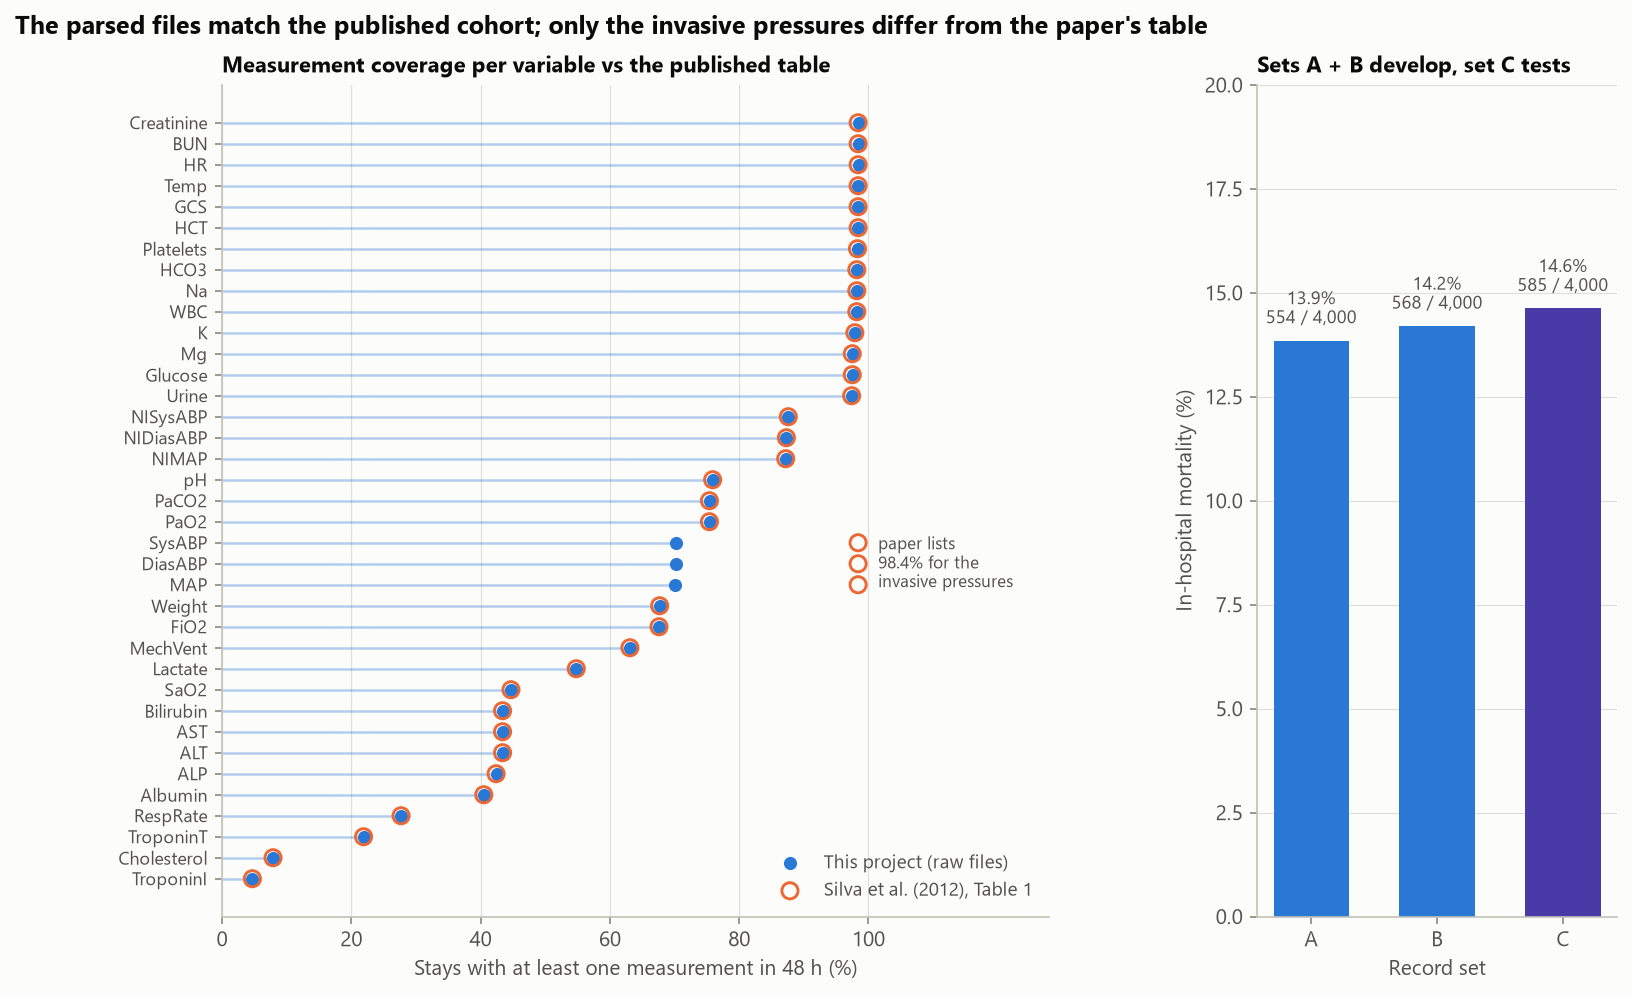

In [7]:
display(Image(FIG / '00_data.png'))

## 2. The measurement process is informative

Whether a laboratory value was ordered at all says a lot about the patient. Among stays in sets A and B, mortality
is 18.1% when lactate was measured in the first 48 hours and 9.0% when it was not, 26.4% vs 13.4% for troponin I,
and 16.6% vs 8.5% for FiO2; stays without a single creatinine, BUN or platelet count (1.5%) have about 3% mortality.
The number of sodium measurements alone ranks deaths above survivors with AUROC 0.64. Respiratory rate goes the other
way: across all 12,000 stays it is never charted when mechanical ventilation is recorded (0 of 7,581 stays) and is
charted in 75% of the others, so its presence marks a non-ventilated, lower-risk patient (7.6% mortality against
16.5% in sets A and B).

In [8]:
pd.read_csv(RES / 'missingness.csv').sort_values('auroc_of_count', ascending=False).round(3)

,variable,share_measured,mortality_if_measured,mortality_if_not_measured,measurements_per_stay_survivors,measurements_per_stay_deaths,auroc_of_count
20,Na,0.983,0.142,0.043,3.346,4.227,0.638
9,FiO2,0.677,0.166,0.085,11.460,13.545,0.630
11,Glucose,0.975,0.143,0.040,3.245,4.022,0.627
19,MechVent,0.630,0.163,0.102,11.708,14.574,0.625
16,Lactate,0.550,0.181,0.090,3.544,4.670,0.620
15,K,0.979,0.142,0.047,3.604,4.397,0.620
12,HCO3,0.983,0.142,0.036,3.365,4.048,0.607
4,Bilirubin,0.431,0.191,0.102,1.839,2.118,0.602
3,AST,0.433,0.191,0.102,1.821,2.094,0.602
2,ALT,0.432,0.191,0.102,1.821,2.102,0.602


## 3. Model comparison on set C

All models were developed on sets A and B (6,400 fitting and 1,600 validation stays) and scored once on set C.
Multi-seed models are the mean of five seeds.

- **XGBoost on 341 summary features is the best single model**: AUROC 0.882 [0.868, 0.895], AUPRC 0.592,
  Brier 0.0857.
- **The recurrent nets trail it.** The GRU (the best recurrent model on validation) reaches 0.871, a gap of
  -0.011 [-0.018, -0.003] that is not significant after Holm correction over 33 tests (p = 0.066); GRU-D (0.869,
  Holm p = 0.014) and the LSTM (0.865, Holm p < 0.001) are significantly behind.
- **Logistic regression on the same features** reaches 0.872 AUROC (n.s.) but a lower AUPRC (-0.043, Holm
  p = 0.034).
- **Averaging XGBoost and the GRU adds nothing** (0.883, +0.001, Holm p = 1.0).
- **GRU-D's learned decay does not beat a GRU fed the mask and the time gaps** (-0.0025 AUROC, Holm p = 0.66); the
  GRU beats the LSTM (+0.006, Holm p = 0.042).
- **SAPS-I and SOFA** from the outcome files, recalibrated by logistic regression, reach only 0.652 and 0.632.

Single seeds vary little (AUROC standard deviation 0.0004 for XGBoost, 0.0013-0.0018 for the recurrent nets), so the
ranking is not a seed artefact.

In [9]:
res = pd.read_csv(RES / 'model_results.csv')
cols = ['regime', 'model', 'n_seeds', 'val_auroc', 'auroc', 'auroc_ci_low', 'auroc_ci_high', 'auprc', 'brier',
        'event1', 'event2', 'event2_platt', 'cal_slope', 'ece']
res[cols].sort_values(['regime', 'auroc'], ascending=[True, False])

,regime,model,n_seeds,val_auroc,auroc,auroc_ci_low,auroc_ci_high,auprc,brier,event1,event2,event2_platt,cal_slope,ece
17,A,Blend,1,0.881,0.870,0.855,0.884,0.560,0.090,0.515,50.540,30.596,1.116,0.022
15,A,XGBoost,5,0.876,0.865,0.849,0.880,0.544,0.091,0.523,51.752,22.025,1.083,0.020
16,A,GRU,5,0.866,0.857,0.841,0.871,0.540,0.092,0.503,37.486,29.679,0.976,0.018
14,A,Logistic regression,1,0.851,0.856,0.840,0.871,0.507,0.095,0.477,78.352,51.094,1.122,0.023
12,A,SAPS-I,1,0.658,0.652,0.630,0.676,0.248,0.120,0.255,27.193,29.817,1.052,0.012
13,A,SOFA,1,0.620,0.632,0.608,0.655,0.251,0.120,0.246,179.890,187.914,1.036,0.030
11,A+B,Blend,1,0.878,0.883,0.869,0.896,0.599,0.085,0.532,31.677,27.880,1.075,0.017
3,A+B,XGBoost,5,0.874,0.882,0.868,0.895,0.592,0.086,0.533,26.241,21.228,1.071,0.016
4,A+B,"XGBoost, values only",5,0.875,0.878,0.864,0.892,0.583,0.087,0.523,36.536,34.775,1.058,0.017
2,A+B,Logistic regression,1,0.870,0.872,0.858,0.885,0.549,0.090,0.516,31.044,40.949,0.944,0.018


In [10]:
seeds = pd.read_csv(RES / 'seed_results.csv')
seeds.groupby(['regime', 'model'])[['val_auroc', 'auroc', 'auprc', 'brier']].agg(['mean', 'std']).round(4)

val_auroc             auroc             auprc         brier           
                                              mean        std   mean        std   mean    std   mean        std
regime model                                                                                                   
A      GRU                                   0.861  3.700e-03  0.852  2.900e-03  0.528  0.014  0.094  1.400e-03
       XGBoost                               0.873  4.800e-03  0.862  1.200e-03  0.537  0.007  0.092  6.000e-04
A+B    GRU                                   0.867  2.600e-03  0.868  1.300e-03  0.561  0.007  0.090  5.000e-04
       GRU, measurement process only         0.744  6.600e-03  0.746  5.200e-03  0.301  0.004  0.113  6.000e-04
       GRU, values only                      0.860  1.500e-03  0.863  1.700e-03  0.541  0.004  0.091  3.000e-04
       GRU-D                                 0.864  1.500e-03  0.866  1.700e-03  0.552  0.007  0.090  9.000e-04
       LSTM                                  0.860  3.400e-03  0.861  1.800e-03  0.538  0.006  0.092  7.000e-04
       XGBoost                               0.874  9.000e-04  0.881  4.000e-04  0.591  0.002  0.086  2.000e-04
       XGBoost, measurement process only     0.783  5.000e-04  0.791  7.000e-04  0.359  0.002  0.108  1.000e-04
       XGBoost, values only                  0.874  1.200e-03  0.878  5.000e-04  0.582  0.003  0.087  1.000e-04

In [11]:
sig = pd.read_csv(RES / 'significance.csv')
sig.round(4)

,model,versus,metric,diff,diff_ci_low,diff_ci_high,p,p_holm
0,LSTM,XGBoost,auroc,-1.630e-02,-2.420e-02,-8.700e-03,0.000e+00,9.000e-04
1,LSTM,XGBoost,auprc,-4.140e-02,-6.350e-02,-1.960e-02,4.000e-04,1.080e-02
2,LSTM,XGBoost,brier,4.900e-03,2.700e-03,7.100e-03,0.000e+00,5.000e-04
3,GRU,XGBoost,auroc,-1.070e-02,-1.810e-02,-3.400e-03,4.400e-03,6.590e-02
4,GRU,XGBoost,auprc,-2.350e-02,-4.680e-02,-5.000e-04,4.810e-02,3.977e-01
5,GRU,XGBoost,brier,3.000e-03,8.000e-04,5.200e-03,8.400e-03,1.096e-01
6,GRU-D,XGBoost,auroc,-1.320e-02,-2.100e-02,-5.600e-03,6.000e-04,1.410e-02
7,GRU-D,XGBoost,auprc,-3.310e-02,-5.690e-02,-1.010e-02,7.100e-03,1.000e-01
8,GRU-D,XGBoost,brier,3.800e-03,1.600e-03,6.200e-03,1.200e-03,2.330e-02
9,Blend,XGBoost,auroc,1.100e-03,-2.600e-03,4.700e-03,5.572e-01,1.000e+00


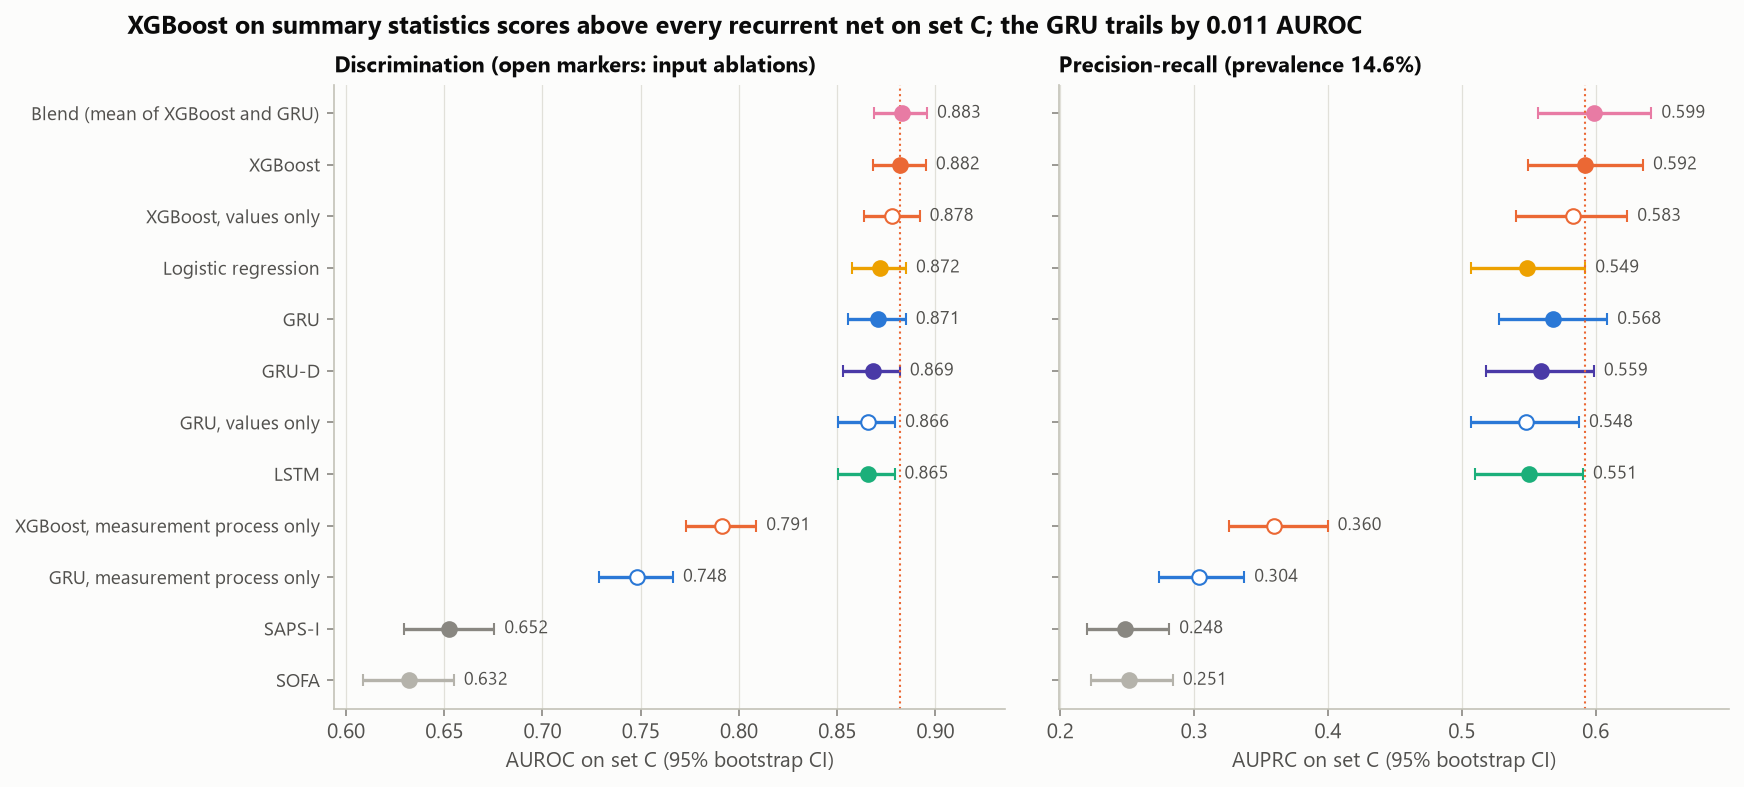

In [12]:
display(Image(FIG / '01_model_comparison.png'))

## 4. Tuning and training

XGBoost had 40 Optuna trials on validation log loss; the best setting uses shallow trees (depth 3), a small learning
rate (0.011) with about 1,800 rounds, and strong column subsampling (23%) and L2 regularisation. The recurrent nets
share one configuration from 20 Optuna trials on the GRU (32 hidden units, dropout 0.19, learning rate 1.2e-3,
batch 256). Early stopping on validation loss ends training after 12-30 epochs on average; the LSTM overfits
fastest (best epoch about 8). Training all 30 recurrent models of both regimes took 1.5 GPU-minutes, the GRU tuning
another 0.8.

In [13]:
tr = pd.read_csv(RES / 'tuning_trials.csv')
tr.groupby(['regime', 'model'])['value'].agg(['count', 'min', 'median'])

count    min  median
regime model                        
A      GRU         12  0.288   0.293
       XGBoost     25  0.278   0.284
A+B    GRU         20  0.284   0.290
       XGBoost     40  0.281   0.282

In [14]:
hist = pd.read_csv(RES / 'training_history.csv')
hist.groupby(['regime', 'model']).agg(epochs=('epoch', 'max'), seconds=('seconds', 'sum')).round(1)

epochs  seconds
regime model                                         
A      GRU                                30      8.9
A+B    GRU                                26      8.3
       GRU, measurement process only      30     10.1
       GRU, values only                   23      6.9
       GRU-D                              21     51.8
       LSTM                               14      4.6

## 5. Calibration and the Event 2 score

Every learned model is close to calibrated on set C: calibration slopes 0.94-1.08 and ECE over risk deciles
1.2-1.8%. All predict slightly too low on average (XGBoost 13.5% vs 14.6% observed), consistent with set C's higher
mortality, and the shortfall sits in the upper half of the risk range. Platt scaling fitted on the validation stays changes
Brier score and ECE only slightly (XGBoost ECE 1.6% to 1.4%).

The challenge's Event 2 score (H / D, lower is better) reacts strongly to small calibration differences. On the risks
as trained (decided before the run), XGBoost scores 26.2 and the GRU 33.4. Single seeds of the same model vary a lot:
26.7-33.8 for XGBoost, 29.6-84.8 for the GRU and 19.2-49.7 for GRU-D, whose five-seed ensemble happens to score best
(19.2). Differences in Event 2 smaller than about a factor of two are therefore within seed noise. Bootstrap
intervals are not reported for Event 2: resampling inflates H, so the bootstrap distribution lies above the point
estimate.

In [15]:
res[res.regime == 'A+B'][['model', 'brier', 'brier_platt', 'ece', 'ece_platt', 'cal_intercept', 'cal_slope',
    'cal_slope_platt', 'hl_stat', 'hl_p', 'event2', 'event2_platt']].round(3)

,model,brier,brier_platt,ece,ece_platt,cal_intercept,cal_slope,cal_slope_platt,hl_stat,hl_p,event2,event2_platt
0,SAPS-I,0.119,0.120,0.011,0.019,0.026,1.008,0.839,5.712,0.679,23.386,53.798
1,SOFA,0.120,0.120,0.030,0.029,0.035,0.993,0.910,36.379,0.000,163.982,176.995
2,Logistic regression,0.090,0.090,0.018,0.018,0.037,0.944,1.026,20.013,0.010,31.044,40.949
3,XGBoost,0.086,0.086,0.016,0.014,0.128,1.071,1.052,15.933,0.043,26.241,21.228
4,"XGBoost, values only",0.087,0.087,0.017,0.016,0.119,1.058,1.032,22.459,0.004,36.536,34.775
5,"XGBoost, measurement process only",0.108,0.108,0.021,0.019,0.127,1.084,1.040,28.350,0.000,71.983,63.130
6,LSTM,0.091,0.091,0.014,0.016,0.125,0.969,1.011,17.888,0.022,29.868,30.694
7,GRU,0.089,0.089,0.016,0.015,0.120,0.942,1.015,21.251,0.007,33.421,30.051
8,GRU-D,0.090,0.090,0.012,0.014,0.074,0.969,1.012,11.860,0.158,19.161,25.558
9,"GRU, values only",0.091,0.090,0.015,0.015,0.150,0.965,1.023,16.755,0.033,27.691,23.841


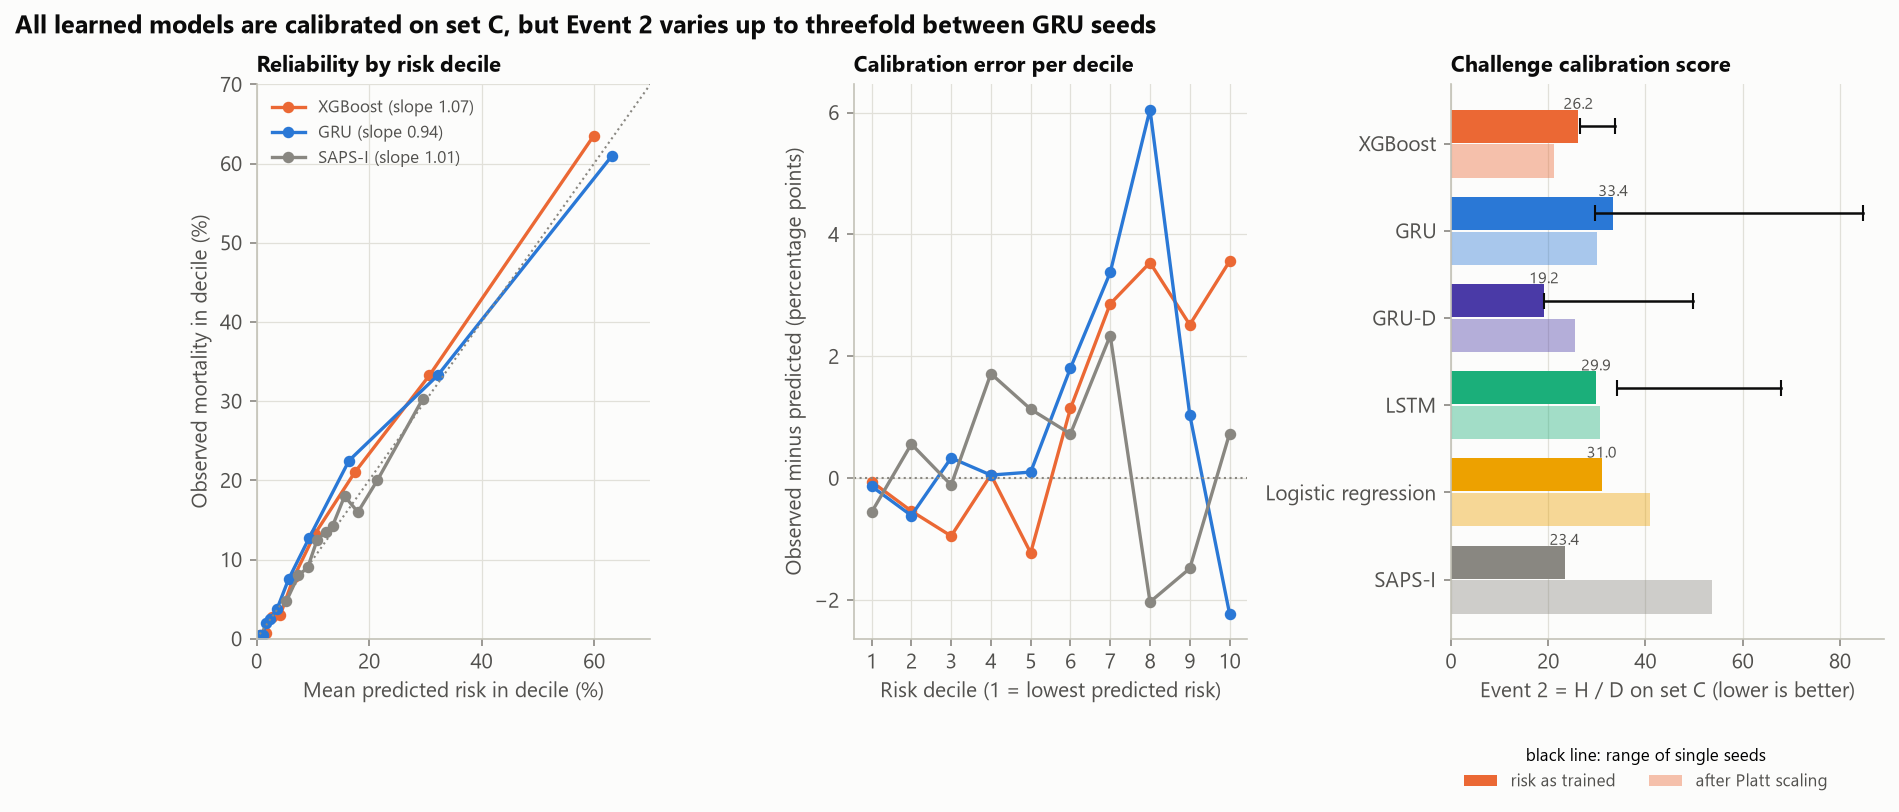

In [16]:
display(Image(FIG / '02_calibration.png'))

## 6. Comparison with the published challenge results

The published final scores are on set C, the same 4,000 stays used as the test set here. Participants had labelled
data for set A only (4,000 stays), so the table also shows models developed on set A alone (3,200 fitting and 800
validation stays, hyperparameters re-tuned).

- **Event 1** (min of sensitivity and positive predictivity at a threshold chosen on validation): XGBoost scores 0.533
  [0.492, 0.573] trained on A + B, just below the winner (0.5353) and the runner-up (0.5345) and well within its
  interval, and 0.523 trained on set A alone; either would have placed third. Its single seeds range from 0.533 to 0.557, so the
  threshold matters as much as the model. The GRU scores 0.525 (A + B) and 0.503 (A).
- **Event 2**: XGBoost trained on A + B scores 26.2 (21.2 after Platt scaling), which would have placed fifth (the
  winner scored 17.88). Trained on set A alone its raw risks are too low for set C (mean 12.9% vs 14.6%) and Event 2
  degrades to 51.8; Platt scaling on 800 validation stays brings it back to 22.0.
- **SAPS-I** from the outcome file reaches Event 1 0.268, below the organisers' SAPS-I sample entries (0.310-0.313),
  which compute their own SAPS-I from the time series; its integer values leave only a coarse choice of thresholds.

Doubling the labelled data from set A to sets A and B raises AUROC by 0.017 for XGBoost and 0.014 for the GRU; the
gap between them is similar in both regimes.

In [17]:
ch = pd.read_csv(RES / 'challenge_comparison.csv')
ch.pivot_table(index=['source', 'entry'], columns='event', values='score', sort=False).round(4)

event                                                                        Event 1    Event 2
source               entry                                                                     
published (set C)    Johnson et al.                                            0.535     29.860
                     Citi and Barbieri                                         0.534     17.880
                     Vairavan et al.                                           0.501        NaN
                     Macas et al.                                              0.493     24.700
                     Xia et al.                                                0.492        NaN
                     Hamilton and Hamilton                                     0.487        NaN
                     Arzeno et al.                                             0.482     51.690
                     Chia et al.                                               0.456        NaN
                     Pantelopoulos                                             0.454        NaN
                     Bera and Nayak                                            0.451     45.010
                     SAPS-I sample entry (m-code)                              0.312     68.580
                     SAPS-I sample entry (C)                                   0.310     35.210
                     Random, 86% predicted to survive                          0.139  10137.700
                     Kang et al.                                                 NaN     20.580
                     Ezeozue                                                     NaN     24.930
                     Kayaalp                                                     NaN     36.380
                     Pollard and Martinez                                        NaN     38.230
                     Bosnjak and Montilla                                        NaN     48.610
this project (set C) XGBoost, trained on sets A+B                              0.533     26.241
                     XGBoost, trained on sets A+B, Platt-scaled                  NaN     21.228
                     GRU, trained on sets A+B                                  0.525     33.421
                     GRU, trained on sets A+B, Platt-scaled                      NaN     30.051
                     Blend, trained on sets A+B                                0.532     31.677
                     Blend, trained on sets A+B, Platt-scaled                    NaN     27.880
                     SAPS-I, trained on sets A+B                               0.268     23.386
                     SAPS-I, trained on sets A+B, Platt-scaled                   NaN     53.798
                     Logistic regression, trained on sets A+B                  0.516     31.044
                     Logistic regression, trained on sets A+B, Platt-scaled      NaN     40.949
                     XGBoost, trained on set A                                 0.523     51.752
                     XGBoost, trained on set A, Platt-scaled                     NaN     22.025
                     GRU, trained on set A                                     0.502     37.486
                     GRU, trained on set A, Platt-scaled                         NaN     29.679
                     Blend, trained on set A                                   0.515     50.540
                     Blend, trained on set A, Platt-scaled                       NaN     30.596
                     SAPS-I, trained on set A                                  0.255     27.193
                     SAPS-I, trained on set A, Platt-scaled                      NaN     29.817
                     Logistic regression, trained on set A                     0.477     78.352
                     Logistic regression, trained on set A, Platt-scaled         NaN     51.094

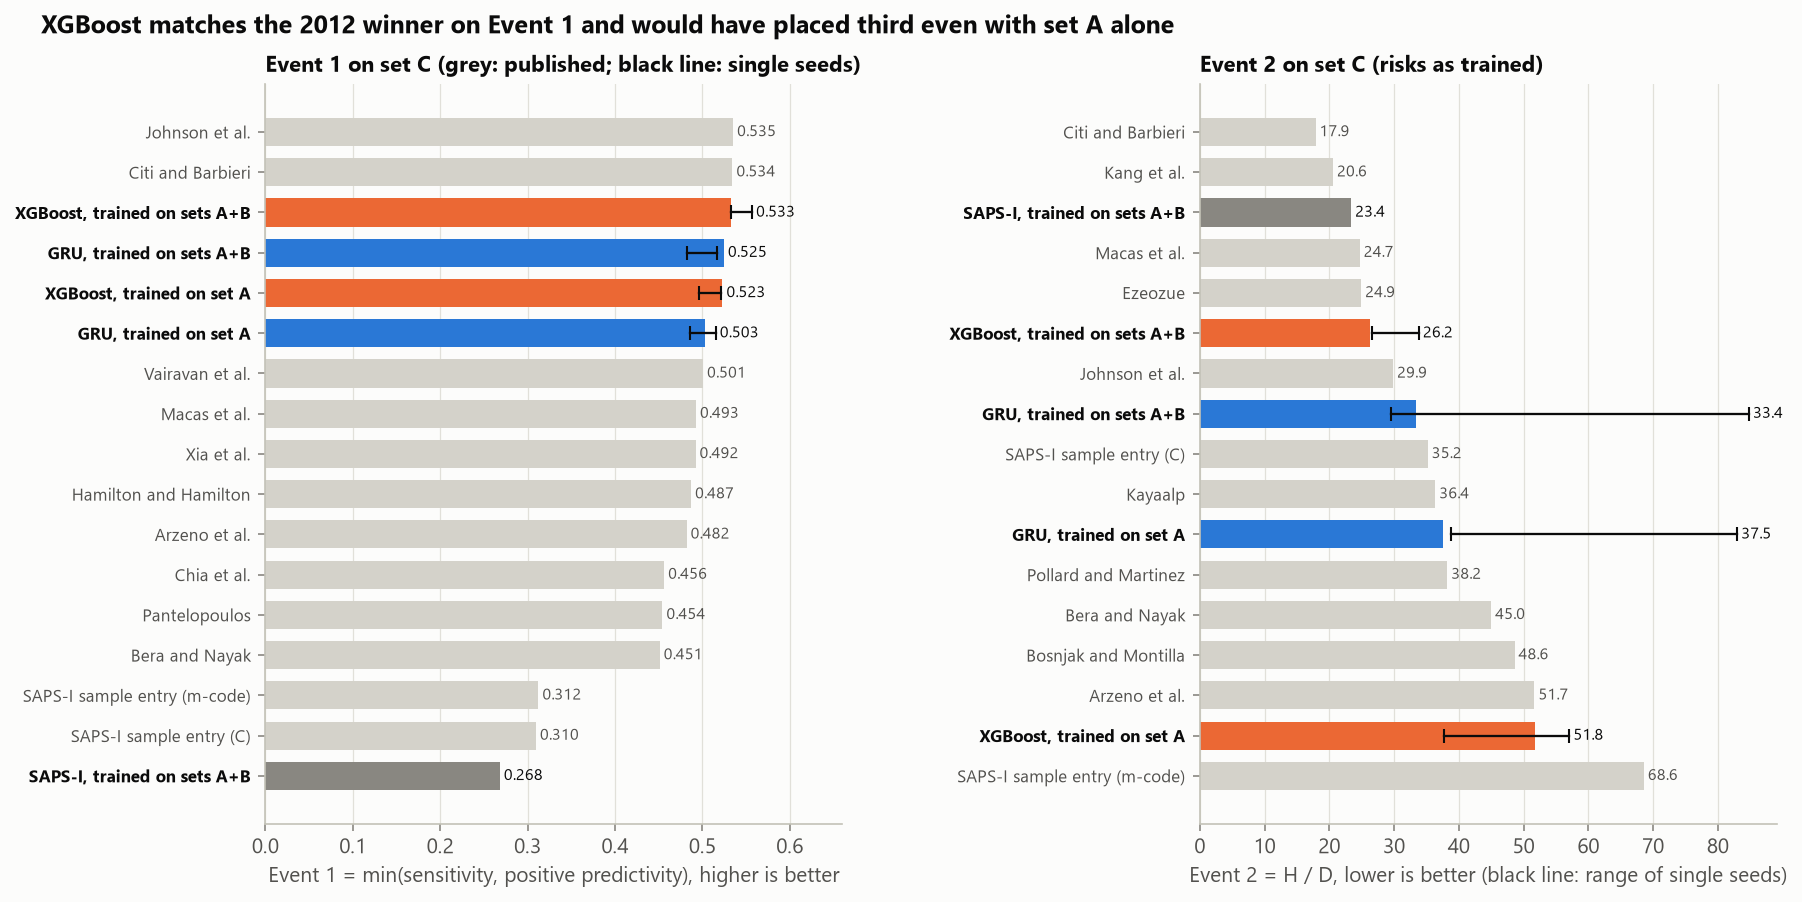

In [18]:
display(Image(FIG / '03_challenge.png'))

## 7. What the models see: values vs measurement process

- **The measurement process alone is strongly predictive.** With only the number and timing of measurements (no
  values, no age, sex or ICU type), XGBoost reaches AUROC 0.791 and the GRU 0.748.
- **For the GRU, the mask and time-gap inputs help**: removing them lowers AUPRC by 0.020 (Holm p = 0.005) and
  AUROC by 0.005 (n.s.).
- **For XGBoost, removing counts and timing costs little** (-0.004 AUROC, n.s.), because a missing summary value
  already tells the tree that a variable was never measured.

In [19]:
abl = res[res.model.str.contains('only') | res.model.isin(['XGBoost', 'GRU'])]
abl[['model', 'auroc', 'auroc_ci_low', 'auroc_ci_high', 'auprc', 'brier']].round(4)

,model,auroc,auroc_ci_low,auroc_ci_high,auprc,brier
3,XGBoost,0.882,0.868,0.895,0.592,0.086
4,"XGBoost, values only",0.878,0.864,0.892,0.583,0.087
5,"XGBoost, measurement process only",0.791,0.773,0.809,0.360,0.108
7,GRU,0.871,0.856,0.885,0.568,0.089
9,"GRU, values only",0.866,0.850,0.880,0.548,0.091
10,"GRU, measurement process only",0.748,0.729,0.766,0.304,0.113
15,XGBoost,0.865,0.849,0.880,0.544,0.091
16,GRU,0.857,0.841,0.871,0.540,0.092


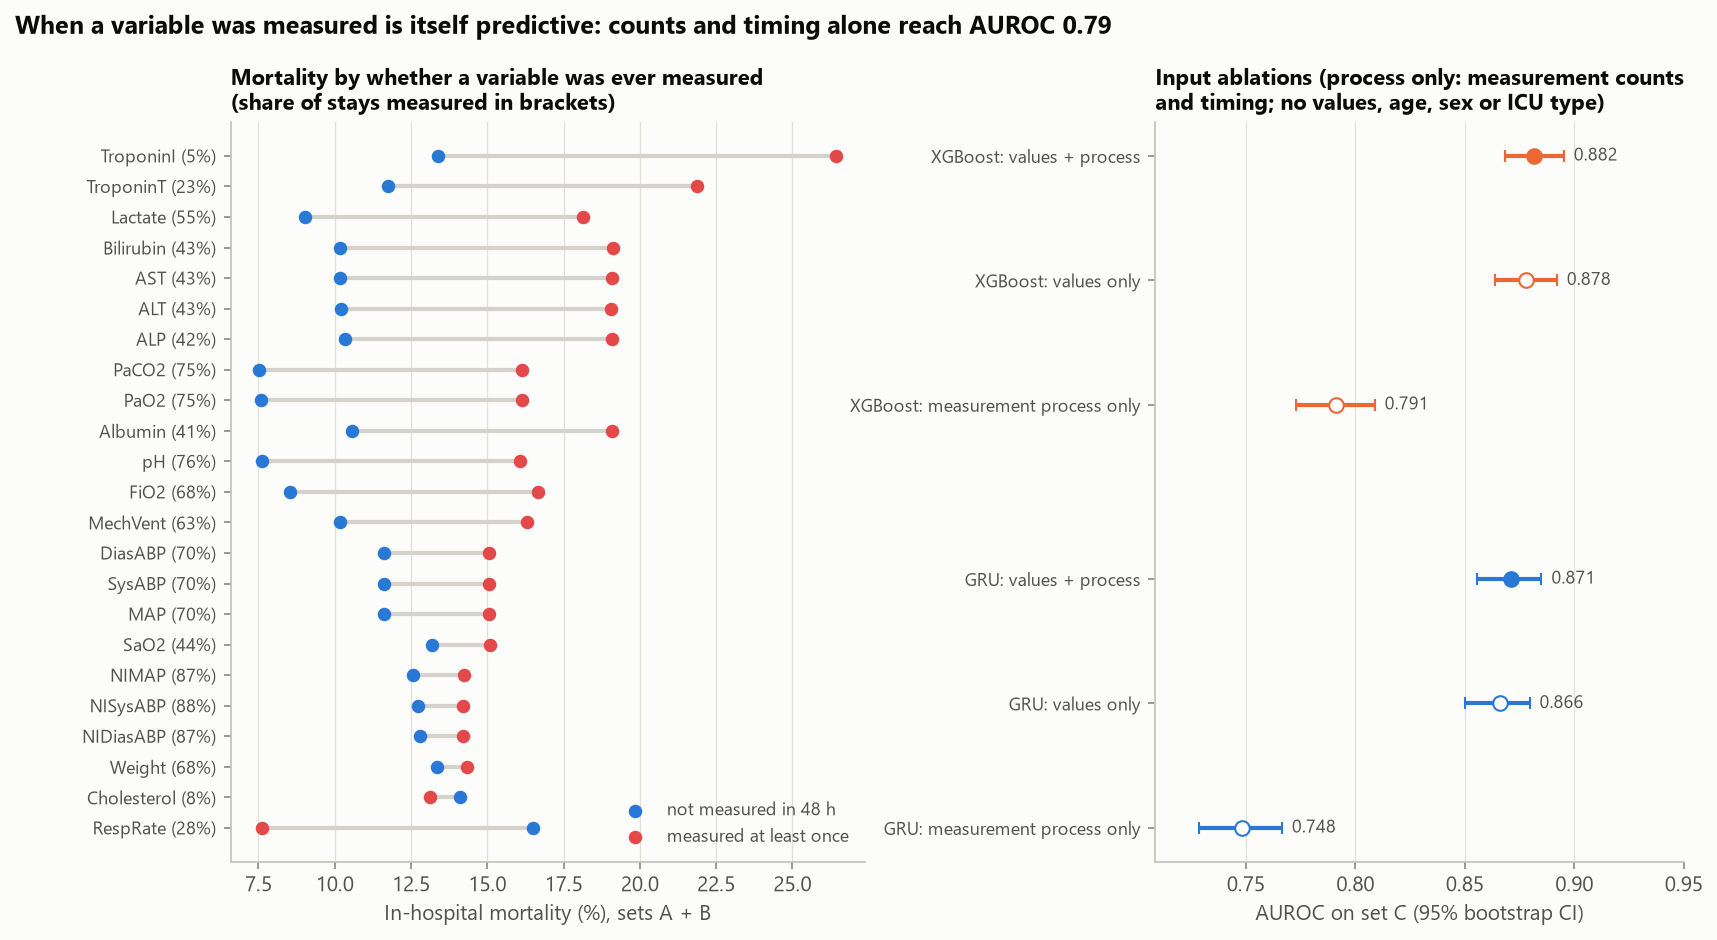

In [20]:
display(Image(FIG / '04_missingness.png'))

## 8. What the models rely on

TreeSHAP on set C puts the Glasgow Coma Score far ahead (0.63 log-odds of mean absolute contribution, summed over its
nine features), followed by BUN, urine output, temperature and age. The single most important feature is the last
GCS of the 48 hours; risk rises steeply below a GCS of about 10, with age above about 75, with mean charted urine
output below about 75 mL and with BUN above about 30 mg/dL.

Grouped permutation importance (shuffling everything derived from one variable across stays) gives the same leader
for both families: shuffling GCS costs XGBoost 0.087 AUROC and the GRU 0.131. The rankings over 41 variables agree
closely (Spearman 0.80). The GRU's drops are larger for GCS, BUN (0.031 vs 0.011) and ICU type (0.017 vs 0.001).

In [21]:
pd.read_csv(RES / 'shap_variables.csv').head(15).round(3)

,variable,mean_abs_shap
0,GCS,0.633
1,BUN,0.313
2,Urine,0.281
3,Temp,0.232
4,Age,0.220
5,HR,0.150
6,RespRate,0.138
7,Weight,0.137
8,FiO2,0.136
9,Glucose,0.127


In [22]:
pd.read_csv(RES / 'shap_features.csv').head(15).round(3)

,feature,variable,mean_abs_shap
0,GCS__last,GCS,0.398
1,Age,Age,0.220
2,Urine__mean,Urine,0.166
3,GCS__mean,GCS,0.110
4,BUN__last,BUN,0.105
5,GCS__std,GCS,0.102
6,Lactate__last,Lactate,0.094
7,Temp__mean,Temp,0.093
8,BUN__min,BUN,0.092
9,Weight,Weight,0.092


In [23]:
pi = pd.read_csv(RES / 'permutation_importance.csv')
pi.pivot_table(index='variable', columns='model', values='auroc_drop').sort_values(pi.model.iloc[0], ascending=False).head(15).round(4)

model,GRU,XGBoost
variable,,
GCS,0.131,0.087
Urine,0.009,0.012
Age,0.018,0.012
BUN,0.031,0.011
Temp,0.006,0.005
Bilirubin,0.005,0.004
RespRate,0.004,0.004
HR,0.006,0.004
FiO2,0.005,0.003


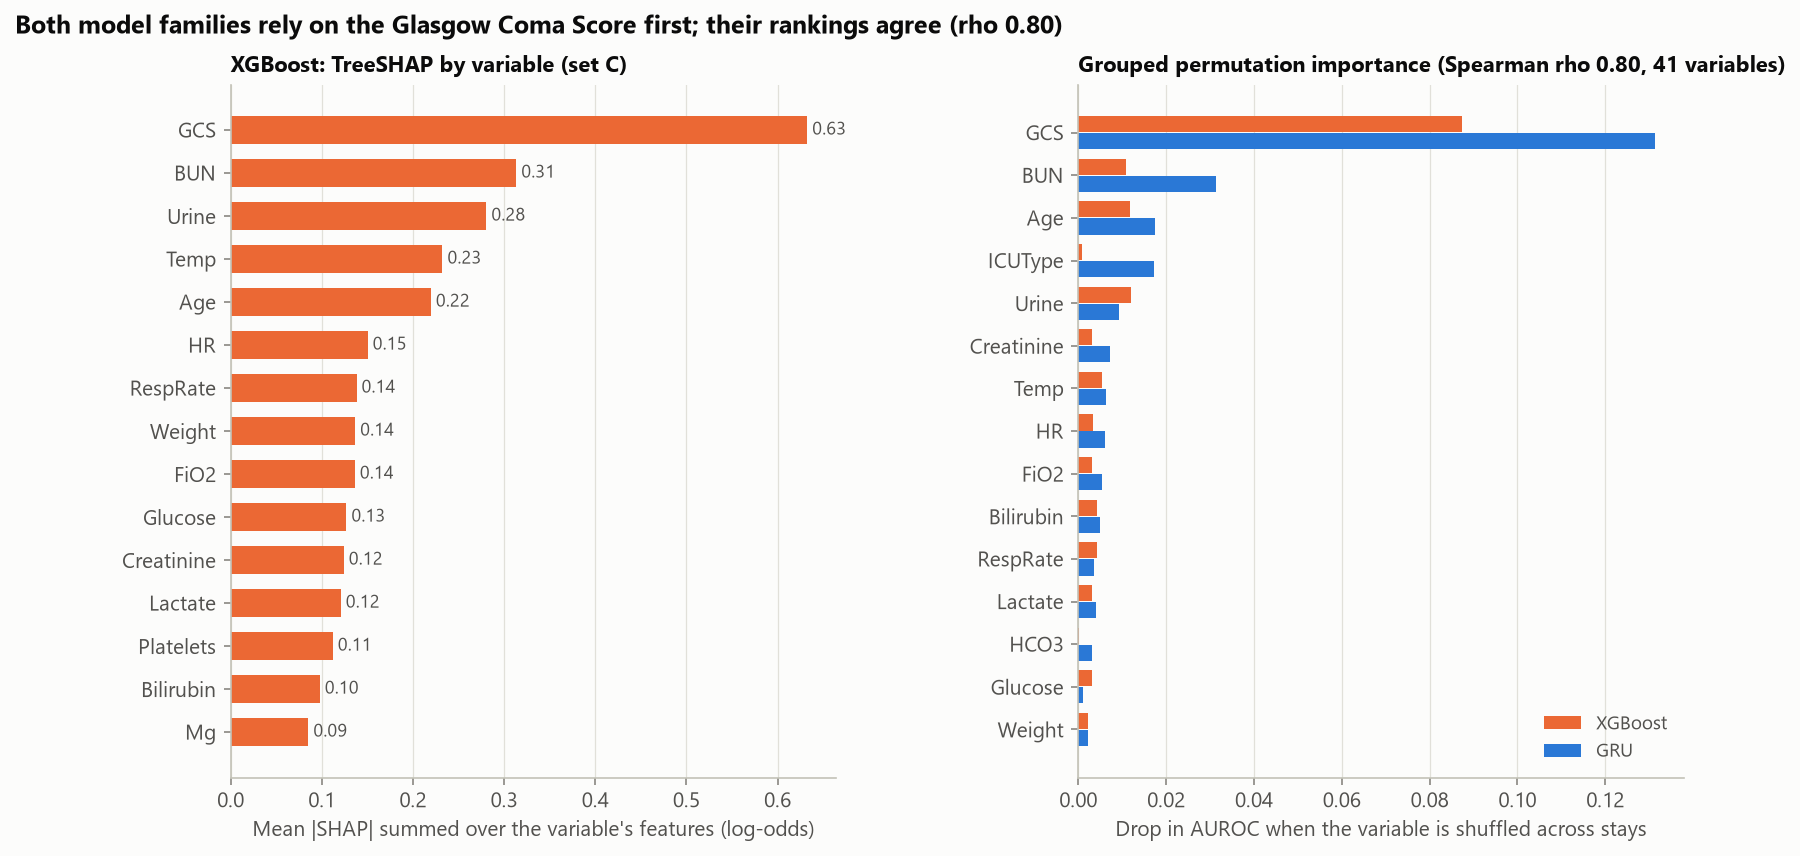

In [24]:
display(Image(FIG / '05_explanations.png'))

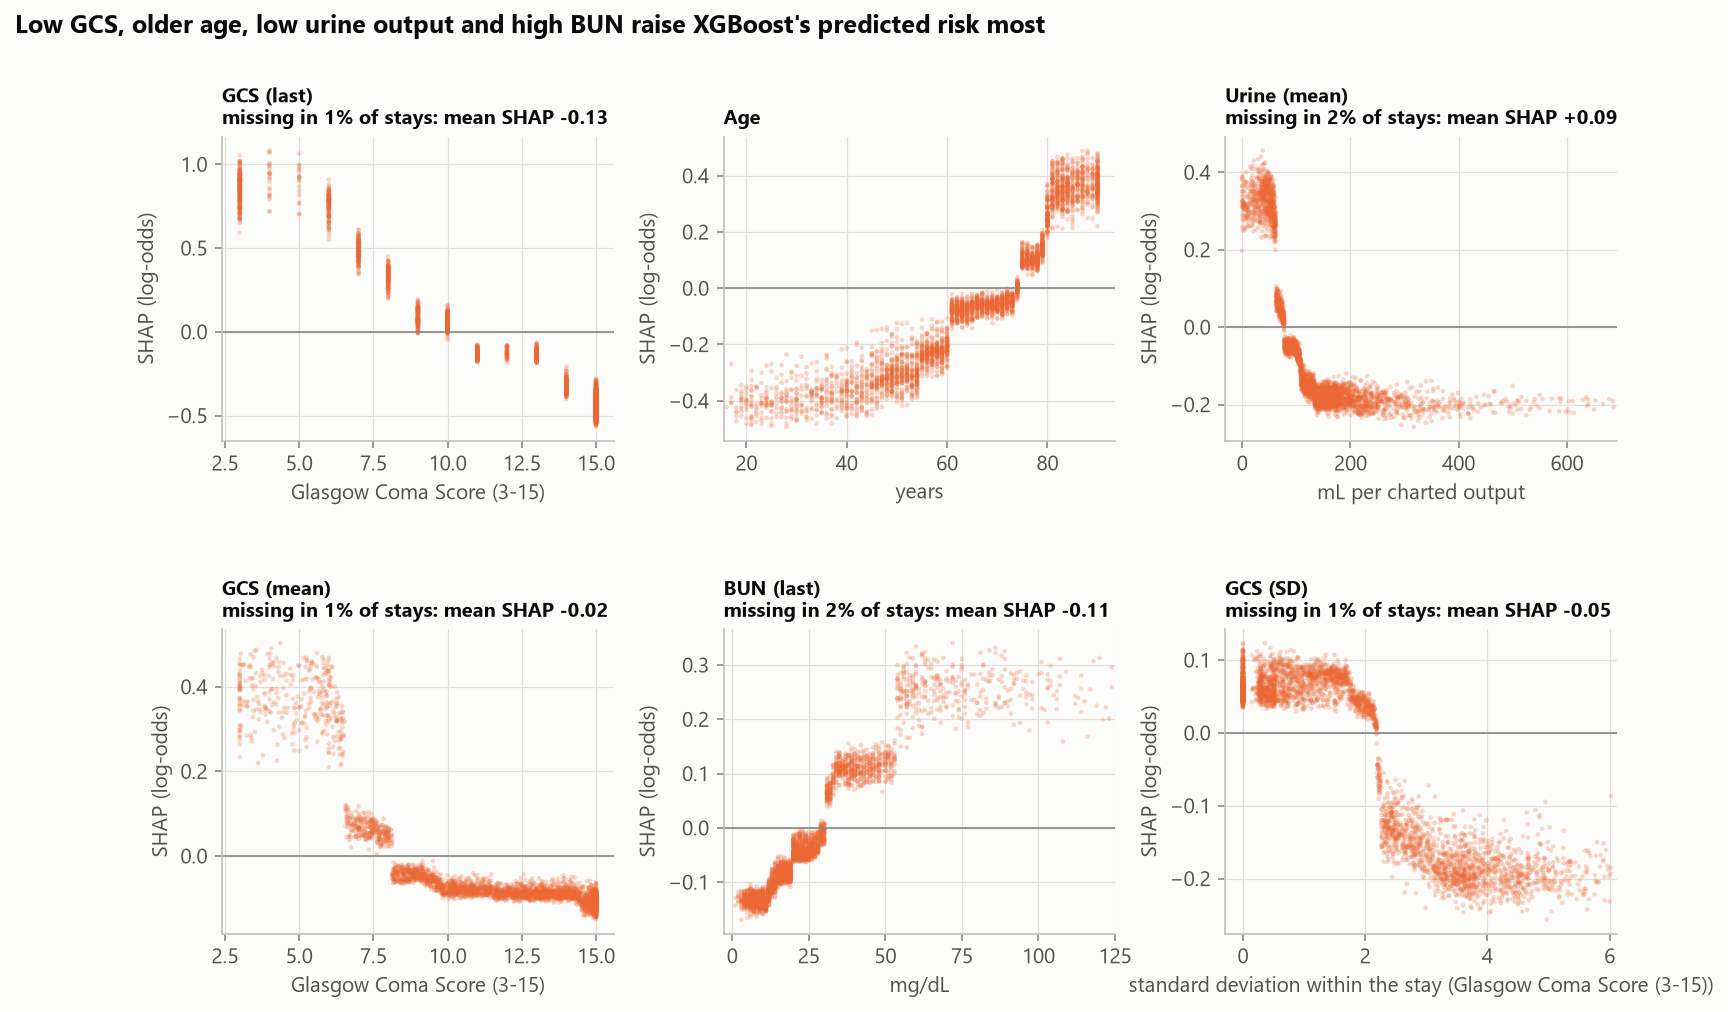

In [25]:
display(Image(FIG / '06_shap_dependence.png'))

## 9. Subgroups

XGBoost and the GRU keep AUROC between 0.81 and 0.91 in every ICU type, age band, sex and ventilation group, far above
SAPS-I (0.62-0.73). Discrimination is lowest for patients aged 80 and over (XGBoost 0.843) and in coronary care for
the GRU (0.806), and highest for patients under 50 (0.911) and in cardiac surgery recovery (0.910), where only 5%
die.

Calibration in the large is less even: for patients aged 80 and over, XGBoost predicts 19.7% mortality against 21.9%
observed (the GRU 18.6%), and the surgical ICU is underestimated by 2 points. At the single Event 1 threshold, the
share of deaths flagged differs widely: 62% of deaths among ventilated patients but 29% among non-ventilated ones, and
39% in cardiac surgery recovery. A deployment would need group-specific thresholds or recalibration.

In [26]:
sg = pd.read_csv(RES / 'subgroups.csv')
sg.pivot_table(index=['grouping', 'group'], columns='model', values=['auroc', 'mean_risk', 'observed_rate',
    'sensitivity'], sort=False).round(3)

auroc               mean_risk               observed_rate               sensitivity              
model                                           XGBoost    GRU SAPS-I   XGBoost    GRU SAPS-I       XGBoost    GRU SAPS-I     XGBoost    GRU SAPS-I
grouping               group                                                                                                                       
ICU type               Cardiac surgery recovery   0.910  0.891  0.650     0.048  0.042  0.175         0.053  0.053  0.053       0.391  0.326  0.457
                       Coronary care              0.845  0.806  0.705     0.121  0.119  0.125         0.118  0.118  0.118       0.437  0.408  0.282
                       Medical                    0.853  0.840  0.665     0.198  0.203  0.138         0.211  0.211  0.211       0.577  0.577  0.241
                       Surgical                   0.879  0.880  0.729     0.134  0.138  0.135         0.154  0.154  0.154       0.537  0.537  0.260
Age                    50-64                      0.886  0.892  0.632     0.106  0.113  0.131         0.117  0.117  0.117       0.512  0.512  0.213
                       65-79                      0.875  0.862  0.623     0.138  0.148  0.159         0.152  0.152  0.152       0.538  0.533  0.307
                       80+                        0.843  0.823  0.640     0.197  0.186  0.158         0.219  0.219  0.219       0.529  0.508  0.286
                       <50                        0.911  0.899  0.669     0.102  0.093  0.116         0.094  0.094  0.094       0.571  0.571  0.214
Sex                    Female                     0.880  0.871  0.644     0.150  0.149  0.145         0.161  0.161  0.161       0.547  0.551  0.267
                       Male                       0.883  0.872  0.660     0.124  0.127  0.142         0.135  0.135  0.135       0.520  0.500  0.270
Mechanical ventilation Not ventilated             0.848  0.825  0.677     0.094  0.092  0.096         0.103  0.103  0.103       0.291  0.291  0.053
                       Ventilated                 0.891  0.885  0.619     0.159  0.162  0.170         0.171  0.171  0.171       0.618  0.606  0.343

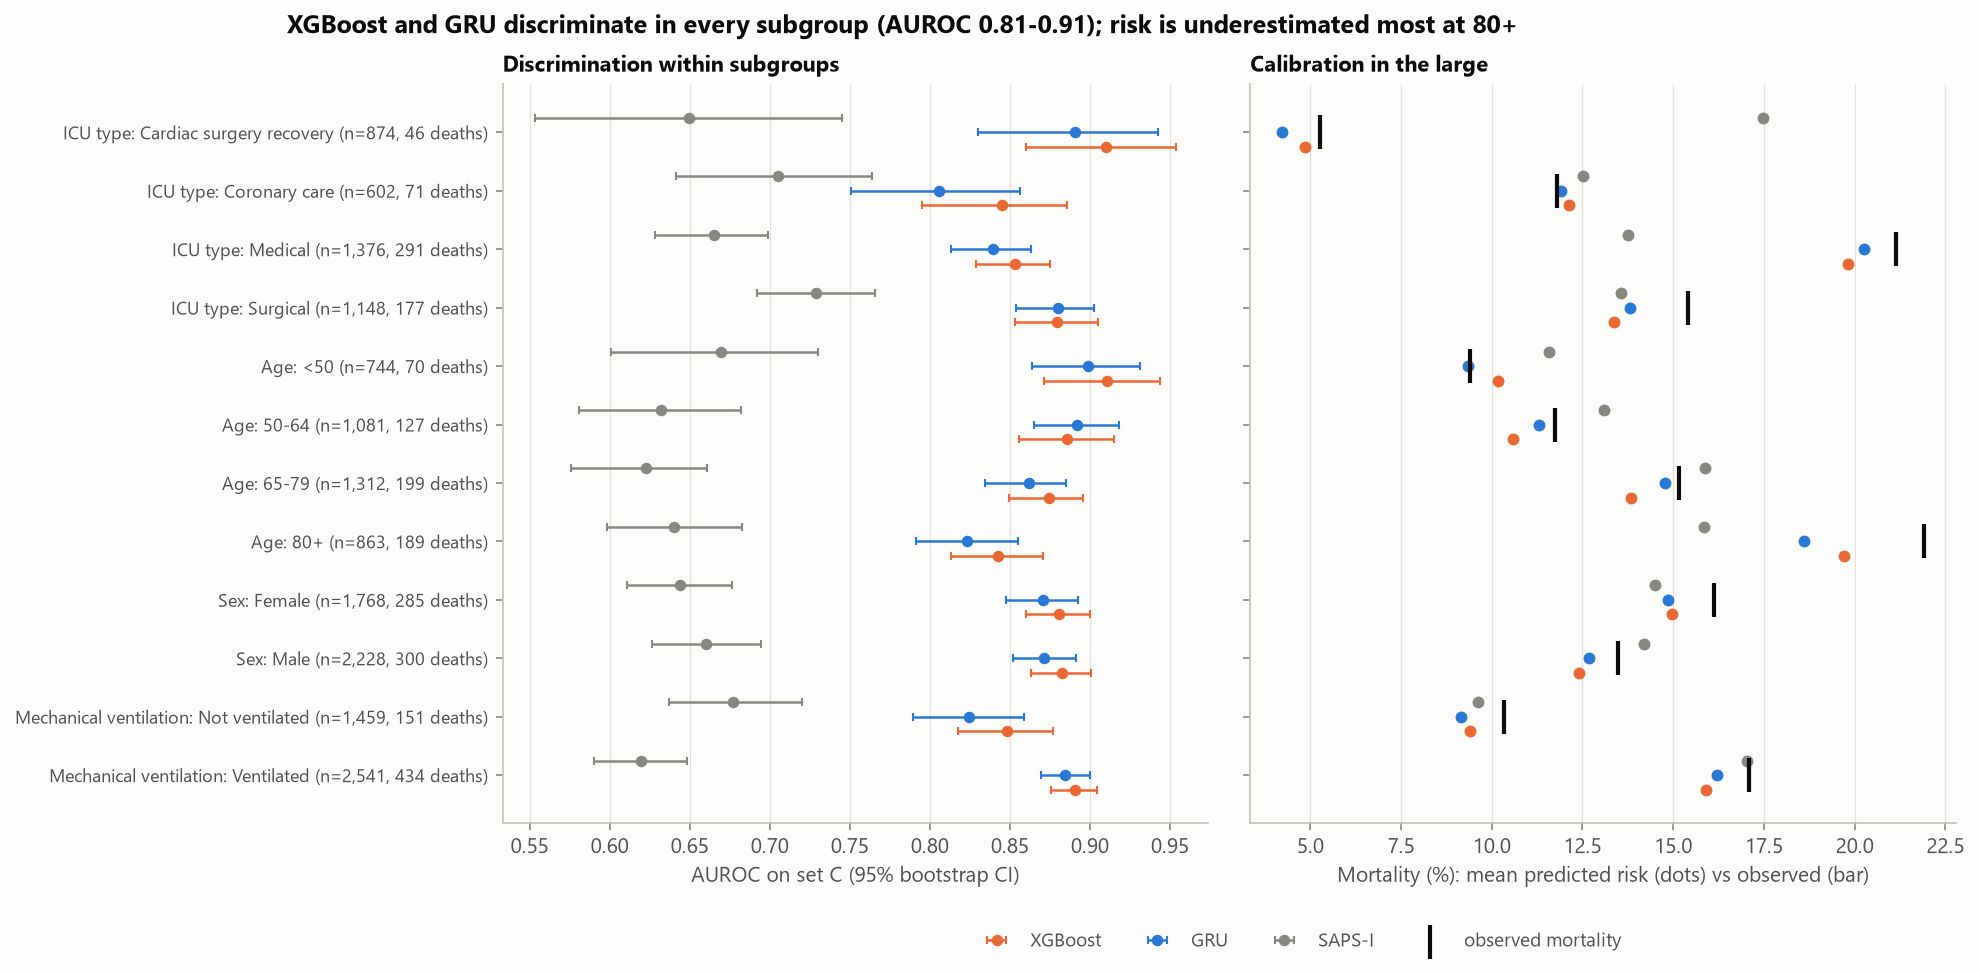

In [27]:
display(Image(FIG / '07_subgroups.png'))

## Takeaways

1. On this benchmark, gradient-boosted trees on 341 simple summary statistics are at least as good as recurrent nets
   that read the hourly sequences; GRU-D's decay mechanism adds nothing over a GRU given the mask and time gaps.
2. A large part of the signal lies in which tests were ordered and how often, not in their values; both model
   families exploit it, the trees implicitly through missing values.
3. XGBoost reaches the level of the best 2012 challenge entries on Event 1, also when restricted to the labelled data
   the participants had; Event 2 is too sensitive to calibration noise to separate good models reliably.
4. Both families agree that consciousness (GCS), renal function (BUN, urine output) and age drive the predictions.
5. Performance holds across subgroups, but calibration and sensitivity at a fixed threshold do not; older patients
   are underestimated.